# Generate a small run and look at its channel powers

This notebook generates a small run with CSIGen in the Los Angeles scene at 28 GHz. It takes the channels of one sector and shows the scene with the base station and the users. Then it plots the power of the channels and the distance of the users, separately for the users with and without a LoS path to this sector.

It needs Sionna RT, as in `requirements.txt`, and runs best on a GPU. Without a GPU, Sionna RT runs on the CPU through LLVM, which is slower.

In [1]:
import sys
import warnings
import yaml
from pathlib import Path


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "scripts" / "run.py").is_file():
            return p
    raise RuntimeError(
        "Cannot find scripts/run.py. "
        "Use working directory CSIGen (repo root) or a folder inside it."
    )


# Imports from repo (needs CSIGen root on sys.path)
REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from sionna.rt import (load_scene, Receiver)
from src.base_station import set_tx_antenna_array, add_base_station
from src.user_equipment import set_rx_antenna_array
import numpy as np
import matplotlib.pyplot as plt
import copy
import os
import subprocess
import tempfile
from pathlib import PurePath

`normalize_channels` scales the channels to unit mean power, over all channels or per channel. The notebook keeps the raw channels, so that the plots show the true channel gain. To see the normalized channels, use it in the cell that defines `channels`.

In [2]:
def normalize_channels(
    channels: np.ndarray,
    *,
    per_sample: bool = False,
    eps: float = 1e-30,
) -> np.ndarray:
    """
    Normalize complex channels by power normalization.

    Divides each channel coefficient by sqrt(mean power), so that
    the normalized channel has unit mean power: E[|H_norm|^2] = 1.

    Args:
        channels:   Complex array of any shape, where axis 0 is the sample axis.
        per_sample: If True, normalize each sample by its own power (removes path loss,
                    isolates small-scale fading structure).
                    If False, normalize by global mean power across the entire array.
        eps:        Small constant to avoid division by zero.

    Returns:
        Power-normalized complex array of same shape, dtype complex64.
    """
    h = np.asarray(channels)

    if not np.iscomplexobj(h):
        raise ValueError(f"`channels` must be complex; got dtype={h.dtype}")

    if per_sample:
        sample_axes = tuple(range(1, h.ndim))
        mean_power = np.mean(np.abs(h) ** 2, axis=sample_axes, keepdims=True)

        clipped = mean_power < eps
        if np.any(clipped):
            n_clipped = int(np.sum(clipped))
            warnings.warn(
                f"{n_clipped} sample(s) have mean_power < eps={eps:.3e}; "
                "eps will be used as the denominator for those samples. "
                "Check for zero or near-zero channels.",
                RuntimeWarning,
                stacklevel=2,
            )
    else:
        mean_power = np.mean(np.abs(h) ** 2)

        if mean_power < eps:
            warnings.warn(
                f"Global mean_power={mean_power:.3e} < eps={eps:.3e}; "
                "eps will be used as the denominator. "
                "Check for zero or near-zero channels.",
                RuntimeWarning,
                stacklevel=2,
            )

    mean_power = np.maximum(mean_power, eps)
    h_norm = h / np.sqrt(mean_power)

    return h_norm.astype(np.complex64, copy=False)

## Generate a small run

This cell starts from `config/examples/urban/la_28ghz.yaml` and changes a few keys to keep the run small and quick. It uses two base stations with three sectors each, a horizontal array of 8 antennas, and samples 20 users per sector. The config also solves every sector for all users of the run (`path_solver_per_tx_users_only: false`). Then it writes the config to a temporary file and runs `scripts/run.py` on it. The run goes to `output/la_1/<timestamp>/`, with one file `channel_tx_<i>.npz` per sector. Each file holds the channels from its sector to all users of the run. The base stations of this config are placed on the highest rooftops, so `num_deployment_buildings` sets their number.

In [3]:
BASELINE_LA = yaml.safe_load(
    (REPO_ROOT / "config/examples/urban/la_28ghz.yaml").read_text()
)

CUSTOM_CONFIG = copy.deepcopy(BASELINE_LA)
# LA scene, compact run: 2 BS, 3 sectors, horizontal 8-element ULA, 20 users sampled per TX
# num_deployment_buildings sets the number of base stations only for configs with rooftop placement.
# A config with bs_positions places its own masts and ignores it.
CUSTOM_CONFIG["num_deployment_buildings"] = 2
CUSTOM_CONFIG["num_sectors"] = 3
CUSTOM_CONFIG["tx_num_rows"] = 1
CUSTOM_CONFIG["tx_num_cols"] = 8
CUSTOM_CONFIG["num_user_samples_per_tx"] = 20

# Write the config to a temporary file, run the generator, then delete the file
# (in the repo root, so that the run log shows only its file name)
fd, cfg_name = tempfile.mkstemp(suffix=".yaml", dir=REPO_ROOT)
cfg_path = Path(cfg_name)
with os.fdopen(fd, "w") as f_out:
    yaml.dump(CUSTOM_CONFIG, f_out, sort_keys=False, allow_unicode=True)

try:
    subprocess.run(
        [sys.executable, "scripts/run.py", "--config", cfg_path.name],
        cwd=str(REPO_ROOT),
        check=True,
    )
finally:
    cfg_path.unlink()

2026-11-02 03:31:40,107 - __main__ - INFO - Loading and validating configuration from tmp1a3d9pyq.yaml
2026-11-02 03:31:40,107 - src.config_validator - INFO - Loading configuration from tmp1a3d9pyq.yaml
2026-11-02 03:31:40,110 - src.config_validator - INFO - Configuration validation successful!
2026-11-02 03:31:40,110 - __main__ - INFO - Starting channel generation (streaming per TX)...
2026-11-02 03:31:40,110 - src.channel_generator - INFO - Step 1: Setting up scene...
2026-11-02 03:31:40,287 - src.scene_setup - INFO - Created ground material itu_asphalt_concrete (thickness 0.100 m)
2026-11-02 03:31:40,288 - src.scene_setup - INFO - Overrode ground material to itu_asphalt_concrete


2026-11-02 03:31:40 WARN  [HDRFilm] Monochrome mode enabled, setting film output pixel format to 'luminance' (was rgb).


2026-11-02 03:31:40,318 - src.scene_setup - INFO - Building bounds: x=[-491.7, 488.2], y=[-463.5, 515.8]
2026-11-02 03:31:40,321 - src.utils - INFO - Clipped terrain: clamped 51253/194617 vertices to bounds
2026-11-02 03:31:40,321 - src.utils - INFO -   Bounds: x=[-506.7, 503.2], y=[-478.5, 530.8]
2026-11-02 03:31:40,330 - src.channel_generator - INFO - Step 2: Setting antenna arrays...
2026-11-02 03:31:40,330 - src.base_station - INFO - Antenna Array Configuration Set:
2026-11-02 03:31:40,330 - src.base_station - INFO -   - Array: 1x8 (8 elements)
2026-11-02 03:31:40,330 - src.base_station - INFO -   - Pattern: tr38901, Polarization: V
2026-11-02 03:31:40,330 - src.base_station - INFO -   - Spacing: V=0.5λ, H=0.5λ
2026-11-02 03:31:40,330 - src.base_station - INFO -   - Estimated beamwidth: [12.75]°
2026-11-02 03:31:40,330 - src.user_equipment - INFO - UE Antenna Array Configuration Set:
2026-11-02 03:31:40,330 - src.user_equipment - INFO -   - Array: 1x1 (1 elements)
2026-11-02 03:31:

Saved channel data to output/la_1/20261102_033140/channel_tx_0.npz
  Shape: (114, 1, 1, 8, 14, 32)
  Dtype: complex64
  Paths: 501
  Metadata keys: ['tx_idx', 'tx_name', 'tx_position', 'tx_orientation', 'rx_positions', 'rx_names', 'los_binary', 'num_txs', 'users_per_tx', 'rx_serving_tx', 'total_users', 'num_sectors', 'num_valid_channels', 'path_buffer_fill', 'rx_velocities', 'rx_orientations', 'cfr_saved', 'cfr_shape', 'cfr_dtype', 'cfr_axes', 'cfr_params', 'cfr_source', 'paths_saved', 'tx_array', 'rx_array', 'config', 'scene_sha256', 'path_stats', 'path_stats_fields', 'path_fields']
Saved channel data to output/la_1/20261102_033140/channel_tx_1.npz
  Shape: (114, 1, 1, 8, 14, 32)
  Dtype: complex64
  Paths: 501
  Metadata keys: ['tx_idx', 'tx_name', 'tx_position', 'tx_orientation', 'rx_positions', 'rx_names', 'los_binary', 'num_txs', 'users_per_tx', 'rx_serving_tx', 'total_users', 'num_sectors', 'num_valid_channels', 'path_buffer_fill', 'rx_velocities', 'rx_orientations', 'cfr_saved',

## Pick one sector

The cell takes the newest run of the scene and one sector file. The file holds the channels from this sector to all users of the run, not only to the users that the sector serves. Its index is `BS_IDX * NUM_SECTORS + SECTOR_IDX`, so change `BS_IDX` and `SECTOR_IDX` to look at another sector.

In [4]:
# Folder nested under scenes/ (./scenes/la_1/scene.xml → la_1)
_city = PurePath(str(CUSTOM_CONFIG["scene_xml_path"]))
city = _city.parent.name

out_root = REPO_ROOT / "output" / city
run_dirs = sorted(p for p in out_root.glob("*") if p.is_dir())
if not run_dirs:
    raise RuntimeError(f"No output runs under {out_root}")
data_dir = run_dirs[-1]
print(f"Using latest generation folder: {data_dir.relative_to(REPO_ROOT)}")

dataset_name = "notebook_generated"
npz_files = sorted(
    data_dir.glob("channel_tx_*.npz"),
    key=lambda p: int(p.stem.rsplit('_', maxsplit=1)[-1]),
)

NUM_SECTORS = int(CUSTOM_CONFIG["num_sectors"])

# select a BS and sector to analyze
# each (BS, sector) pair is saved in a separate .npz file
BS_IDX = 0
SECTOR_IDX = 0
file_idx = BS_IDX * NUM_SECTORS + SECTOR_IDX

npz_file = npz_files[file_idx]
scene_dir = REPO_ROOT / "scenes" / city
scene_xml_path = scene_dir / "scene.xml"
print(f"Loading {npz_file.name} (BS_IDX={BS_IDX}, SECTOR_IDX={SECTOR_IDX}, file_idx={file_idx})")


Using latest generation folder: output/la_1/20261102_033140
Loading channel_tx_0.npz (BS_IDX=0, SECTOR_IDX=0, file_idx=0)


## Load the channels and the metadata

`h` is the channel frequency response (CFR) with the axes `[rx, rx_ant, tx, tx_ant, ofdm_symbol, subcarrier]`. Each user has one antenna and each file has one sector, so `np.squeeze` gives `[user, BS antenna, OFDM symbol, subcarrier]`. The metadata holds the config of the run, the positions of the base station and the users, and the LoS flag of each user (`los_binary`), among others.

In [5]:
with np.load(npz_file, allow_pickle=True) as data:
    print("The shape of the data is ", data["h"].shape)

    # Read metadata and antenna geometry
    meta = data["metadata"].item()
    cfg = meta["config"]

    # Antenna array geometry (must be present in metadata)
    if "tx_num_rows" not in cfg or "tx_num_cols" not in cfg:
        raise RuntimeError(
            "Antenna geometry not found in metadata config "
            "(expected 'tx_num_rows' and 'tx_num_cols')."
        )

    # Subcarrier spacing from config is stored in Hz
    if "subcarrier_spacing" not in cfg:
        raise RuntimeError("Expected 'subcarrier_spacing' in metadata config.")

    n_rows = int(cfg["tx_num_rows"])
    n_cols = int(cfg["tx_num_cols"])
    subcarrier_spacing_hz = float(cfg["subcarrier_spacing"])
    subcarrier_spacing_khz = subcarrier_spacing_hz / 1e3

    print(f"Antenna array geometry: {n_rows}x{n_cols}")
    print(f"Subcarrier spacing: {subcarrier_spacing_khz} kHz")

    tx_name = meta.get("tx_name")
    if tx_name is None:
        raise RuntimeError("Expected 'tx_name' in metadata.")

    base_name = f"{dataset_name}_{city}_{tx_name}"

    # Get rid of singleton axes (e.g. (N, 1, 1, ...)) so that
    # the first axis is samples/users and the rest are channel dimensions.
    h = np.squeeze(data["h"])

print("Squeezed data shape: ", h.shape)
print(
    "Loaded ",
    h.shape[0],
    " channels",
    "with shape ",
    h.shape[1:],
)

The shape of the data is  (114, 1, 1, 8, 14, 32)
Antenna array geometry: 1x8
Subcarrier spacing: 30.0 kHz
Squeezed data shape:  (114, 8, 14, 32)
Loaded  114  channels with shape  (8, 14, 32)


This cell prints the share of the users that have a LoS path to this sector.

In [6]:
print(f"There are {meta['los_binary'].sum()/meta['los_binary'].size*100:.1f}% LOS samples")

There are 53.5% LOS samples


## Show the scene

These cells load the scene with Sionna RT and add the base station with the arrays and sectors of the config. Then they add all users of the run, in blue if they have a LoS path to this sector and in green if not. `scene.preview()` opens an interactive 3D view. It needs a notebook front end that shows widgets, such as JupyterLab. A static view such as GitHub shows nothing.

In [7]:
# channels = normalize_channels(h)
channels = h
scene = load_scene(scene_xml_path, merge_shapes=True)
# Base name for add_base_station (sectors are BS_X_sector_1, …)
bs_base = f"BS_{BS_IDX}"

tx_position = meta.get("tx_position")
rx_positions = meta.get("rx_positions")
los_indices = np.where(meta["los_binary"] == 1)[0]
nlos_indices = np.where(meta["los_binary"] == 0)[0]


2026-11-02 03:31:51 WARN  [HDRFilm] Monochrome mode enabled, setting film output pixel format to 'luminance' (was rgb).


In [8]:
# let's create a scene to visualize some of the channels from the dataset
set_tx_antenna_array(
    scene,
    num_rows=int(cfg["tx_num_rows"]),
    num_cols=int(cfg["tx_num_cols"]),
    vertical_spacing=float(cfg["tx_vertical_spacing"]),
    horizontal_spacing=float(cfg["tx_horizontal_spacing"]),
    pattern=str(cfg["tx_pattern"]),
    polarization=str(cfg["tx_polarization"]),
)

set_rx_antenna_array(
    scene,
    num_rows=int(cfg["rx_num_rows"]),
    num_cols=int(cfg["rx_num_cols"]),
    vertical_spacing=float(cfg["rx_vertical_spacing"]),
    horizontal_spacing=float(cfg["rx_horizontal_spacing"]),
    pattern=str(cfg["rx_pattern"]),
    polarization=str(cfg["rx_polarization"]),
)

print("Adding base station at ", tx_position)
add_base_station(
    scene,
    bs_base,
    position=list(tx_position),
    num_sectors=int(cfg["num_sectors"]),
    mechanical_tilt=float(cfg["mechanical_tilt"]),
    azimuth_offset=float(cfg["azimuth_offset"]),
    tx_power_dbm=float(cfg["tx_power_dbm"]),
    display_radius=15,
)

for user_idx in los_indices:
    rx = Receiver(
        name=f"UE_{user_idx}",
        position=list(rx_positions[user_idx]),
        display_radius=20,
        color=[0, 0, 1],
    )
    scene.add(rx)

for user_idx in nlos_indices:
    rx = Receiver(
        name=f"UE_{user_idx}",
        position=list(rx_positions[user_idx]),
        display_radius=20,
        color=[0, 1, 0],
    )
    scene.add(rx)

print(f"Added {len(los_indices)} LoS and {len(nlos_indices)} NLoS receivers for preview")


Adding base station at  [[ 54.86833]
 [139.83519]
 [325.9    ]]
Added 61 LoS and 53 NLoS receivers for preview


In [9]:
scene.preview()

## Channel power of the LoS users

The power of a channel is the mean of $|h|^2$ over the BS antennas, the OFDM symbols and the subcarriers, in dB. It is the channel gain, since the CFR is not normalized. The histogram shows its distribution over the LoS users, with the mean (of the linear power) as a red line.

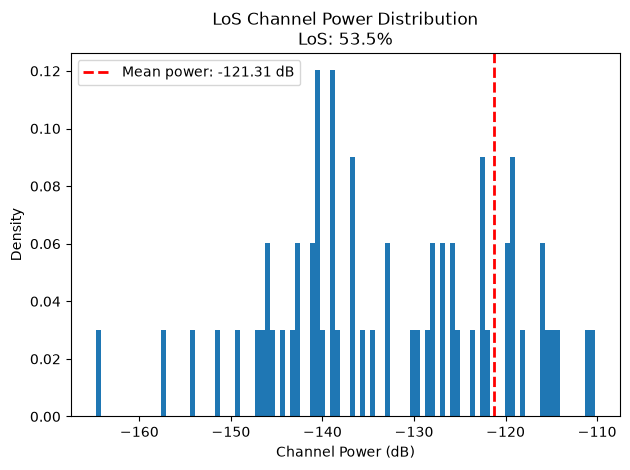

In [10]:
los_sampled_channels = channels[los_indices]
los_channel_power = np.mean(np.abs(los_sampled_channels) ** 2, axis=(1, 2, 3))
los_channel_power_db = 10 * np.log10(los_channel_power)
los_mean_linear_power = los_channel_power.mean()
los_mean_power_db = 10 * np.log10(los_mean_linear_power)

# Percentage of LoS / nLoS samples
los_percentage = meta["los_binary"].sum() / meta["los_binary"].size * 100
nlos_percentage = 100 - los_percentage

plt.hist(los_channel_power_db, bins=100, density=True)
plt.xlabel("Channel Power (dB)")
plt.ylabel("Density")
plt.title(f"LoS Channel Power Distribution\nLoS: {los_percentage:.1f}%")
plt.axvline(
    los_mean_power_db,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean power: {los_mean_power_db:.2f} dB",
)
plt.legend()
plt.tight_layout()
plt.show()


This cell plots the CDF of the same powers, and the CDF of the distance between the base station and each LoS user.

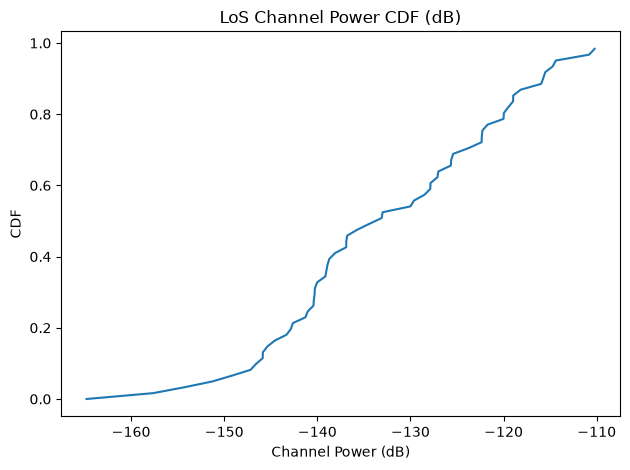

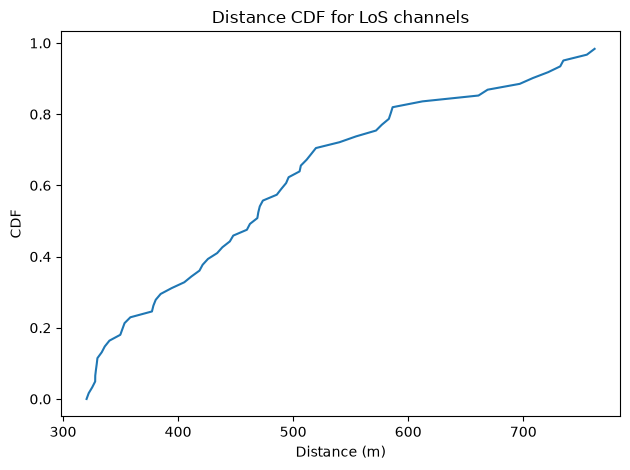

In [11]:
# LoS: CDFs
plt.plot(
    np.sort(los_channel_power_db),
    np.arange(len(los_channel_power_db)) / len(los_channel_power_db),
)
plt.xlabel("Channel Power (dB)")
plt.ylabel("CDF")
plt.title("LoS Channel Power CDF (dB)")
plt.tight_layout()
plt.show()

# LoS: distance CDF (use LoS-only RX positions)
los_rx_positions = rx_positions[los_indices]
los_channel_distances = np.linalg.norm(los_rx_positions - tx_position, axis=(1, 2))
los_distance_cdf_x = np.sort(los_channel_distances)
plt.plot(los_distance_cdf_x, np.arange(len(los_distance_cdf_x)) / len(los_distance_cdf_x))
plt.xlabel("Distance (m)")
plt.ylabel("CDF")
plt.title("Distance CDF for LoS channels")
plt.tight_layout()
plt.show()

## Channel power of the NLoS users

These cells make the same plots for the NLoS users. Their channels reach the user only through reflections, diffraction or refraction, so their power is usually lower than for the LoS users.

Mean linear power of nLoS channels:  3.165231e-14


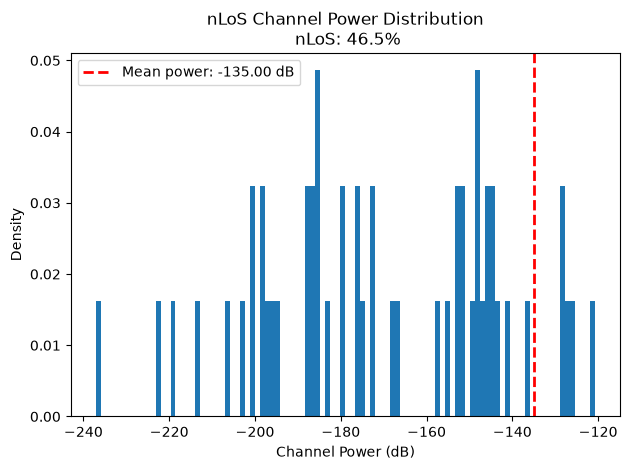

In [12]:
nlos_sampled_channels = channels[nlos_indices]
nlos_channel_power = np.mean(np.abs(nlos_sampled_channels) ** 2, axis=(1, 2, 3))
nlos_channel_power_db = 10 * np.log10(nlos_channel_power)
nlos_mean_linear_power = nlos_channel_power.mean()
nlos_mean_power_db = 10 * np.log10(nlos_mean_linear_power)
print("Mean linear power of nLoS channels: ", nlos_mean_linear_power)

# Percentage of LoS / nLoS samples
los_percentage = meta["los_binary"].sum() / meta["los_binary"].size * 100
nlos_percentage = 100 - los_percentage

# nLoS: histograms
plt.hist(nlos_channel_power_db, bins=100, density=True)
plt.xlabel("Channel Power (dB)")
plt.ylabel("Density")
plt.title(f"nLoS Channel Power Distribution\n nLoS: {nlos_percentage:.1f}%")
plt.axvline(
    nlos_mean_power_db,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean power: {nlos_mean_power_db:.2f} dB",
)
plt.legend()
plt.tight_layout()
plt.show()

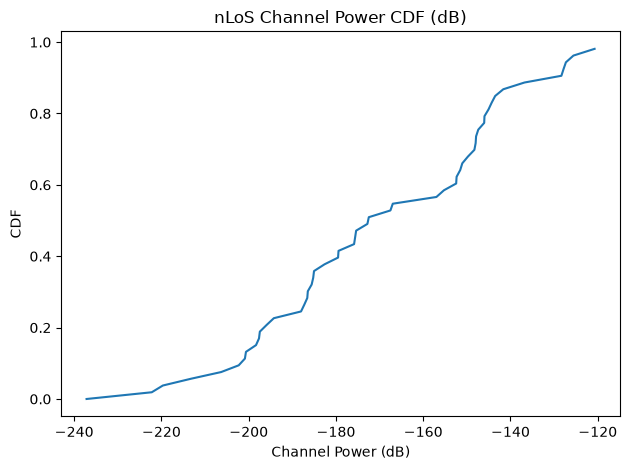

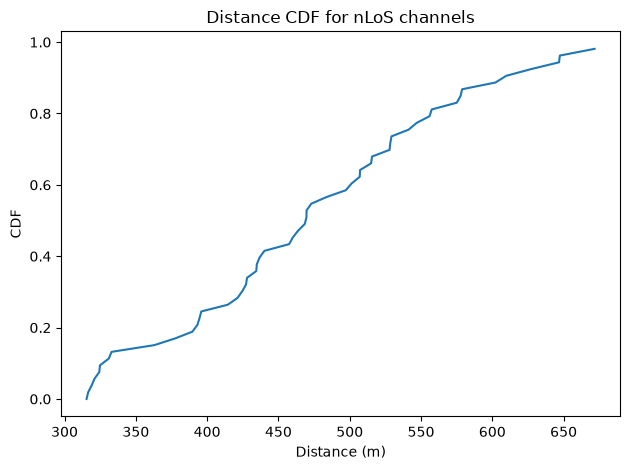

In [13]:
# nLoS: CDFs
plt.plot(
    np.sort(nlos_channel_power_db),
    np.arange(len(nlos_channel_power_db)) / len(nlos_channel_power_db),
)
plt.xlabel("Channel Power (dB)")
plt.ylabel("CDF")
plt.title("nLoS Channel Power CDF (dB)")
plt.tight_layout()
plt.show()

# nLoS: distance CDF (use nLoS-only RX positions)
nlos_rx_positions = rx_positions[nlos_indices]
nlos_channel_distances = np.linalg.norm(nlos_rx_positions - tx_position, axis=(1, 2))
nlos_distance_cdf_x = np.sort(nlos_channel_distances)
plt.plot(nlos_distance_cdf_x, np.arange(len(nlos_distance_cdf_x)) / len(nlos_distance_cdf_x))
plt.xlabel("Distance (m)")
plt.ylabel("CDF")
plt.title("Distance CDF for nLoS channels")
plt.tight_layout()
plt.show()